# House Prices: Linear Regression, Formula First

Two houses in Ames, Iowa sit on the same street. One sells for \$130,000, the other for \$340,000. A buyer sees bricks and windows; a model sees 79 columns. I start with one feature and one straight line, and add only what the formula asks for: which columns to log, which to turn into 0/1 columns, which to drop. A tree model only gets a turn at the end, as a benchmark.

**Data** → [Kaggle competition](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques) · 1,460 sold houses with prices · 1,459 houses to price · 79 features

<!-- objective -->
## Aim and objectives

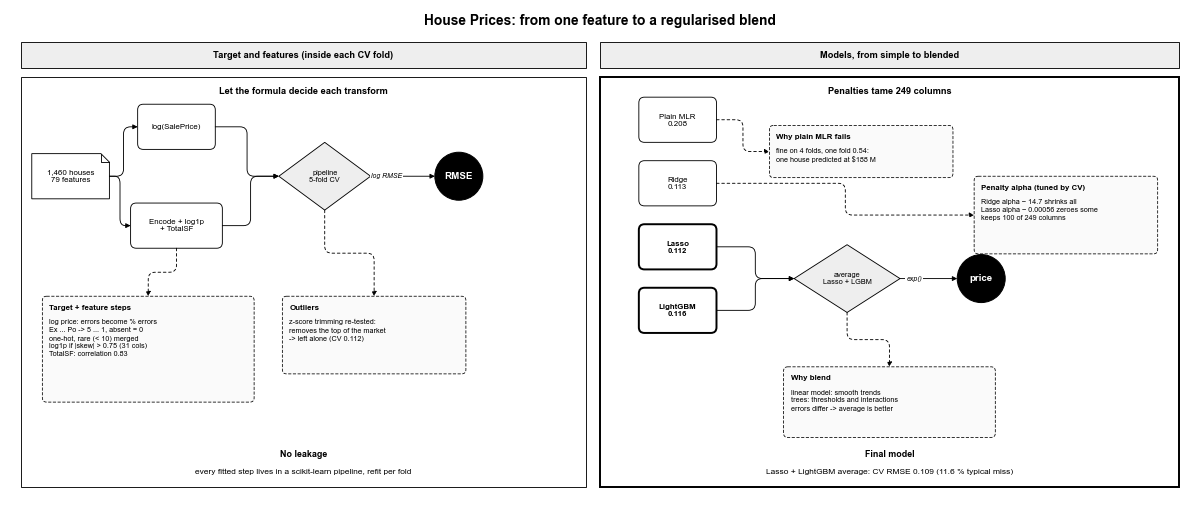

**Aim** → price houses in Ames with a model I can explain line by line, and add complexity only when cross-validation says it helps.

**Objectives**
1. See how prices are spread out, and why the competition scores log prices
2. Find out what one extra square foot is worth, and what a regression line really learns
3. Check which linear regression assumptions break here, and fix them
4. Push plain linear regression to all 79 columns, then calm it down with Ridge / Lasso
5. Test whether a tree model (LightGBM) beats the best linear model

**Where it could help** → a quick price estimate for buyers, sellers and agents, with a typical miss of ~12% and the reasons behind it (size, quality, neighbourhood) to show a client. Today many prices come from gut feeling and a few "comparable" sales, and a 10% mistake on a \$180k house is \$18k.

# [1/11] Setup

Every setting lives in the next cell. Later cells only read them, and nothing is written to disk unless you turn it on there.

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/10] DATA_DIR: competition data folder
    Default = '/kaggle/input/house-prices-advanced-regression-techniques'
[2/10] WORK_DIR: folder for the submission file
    Default = '/kaggle/working'
[3/10] N_FOLDS: cross-validation folds
    Default = 5
[4/10] SEED: random seed
    Default = 42
[5/10] DROP_PARTIAL_GIANTS: drop training houses above 4,000 sq ft sold as partial sales
    Default = True
[6/10] SKEW_LIMIT: |skewness| above which a numeric feature gets log1p
    Default = 0.75
[7/10] MIN_CATEGORY_COUNT: categories rarer than this are merged into one "infrequent" column
    Default = 10
[8/10] RIDGE_ALPHAS / LASSO_ALPHAS: (start, stop, count) of the log10 grid of penalty strengths
    Default = (-1, 3, 25) / (-4.5, -1.5, 25)
[9/10] LGBM_PARAMS: LightGBM benchmark settings
    Default = 2,000 trees of 15 leaves, learning rate 0.01
[10/10] SAVE_SUBMISSION: predict all test houses and write submission.csv
    Default = False
    For example:
        SAVE_SUBMISSION = True
"""
DATA_DIR            = '/kaggle/input/house-prices-advanced-regression-techniques'
WORK_DIR            = '/kaggle/working'
N_FOLDS             = 5
SEED                = 42
DROP_PARTIAL_GIANTS = True
SKEW_LIMIT          = 0.75
MIN_CATEGORY_COUNT  = 10
RIDGE_ALPHAS        = (-1, 3, 25)
LASSO_ALPHAS        = (-4.5, -1.5, 25)
LGBM_PARAMS         = {
    'n_estimators':      2000,
    'learning_rate':     0.01,
    'num_leaves':        15,
    'min_child_samples': 10,
    'subsample':         0.7,
    'subsample_freq':    1,
    'colsample_bytree':  0.5,
    'reg_lambda':        1.0,
    'verbose':           -1,
}
SAVE_SUBMISSION     = False

SUBMISSION_FILE     = f'{WORK_DIR}/submission.csv'
SUBMISSION_PREVIEW  = 10
TARGET              = 'SalePrice'
PAD                 = 30
PALETTE             = {'main': 'black', 'flag': 'red', 'soft': 'grey'}
QUALITY_SCALE       = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1}
QUALITY_COLS        = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
                       'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
ABSENT_MEANS_NONE   = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu',
                       'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import skew, probplot

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMRegressor

import warnings

sns.set_theme(style='darkgrid', palette='gray')
warnings.filterwarnings('ignore', message='X does not have valid feature names')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def qq_plot(values, ax, title):
    (theoretical, ordered), (slope, intercept, _) = probplot(values, dist='norm')
    ax.scatter(theoretical, ordered, s=8, color=PALETTE['main'])
    ax.plot(theoretical, slope * theoretical + intercept, color=PALETTE['flag'])
    ax.set(title=title, xlabel='Normal quantiles', ylabel='Ordered values')

# [2/11] Data

**Aim** → load the CSVs and fill the gaps the right way: most "missing" values just mean the house has no pool, alley, fence, garage or basement.

In [ ]:
from pathlib import Path


def find_competition_dir(default, required_column, root='/kaggle/input'):
    """Folder with train.csv + test.csv whose train.csv has `required_column`.
    Tries `default` first, then searches everything under `root` (Kaggle mount paths differ between setups)."""
    import csv
    candidates = [Path(default)]
    if Path(root).exists():
        candidates += sorted(p.parent for p in Path(root).rglob('train.csv'))
    for folder in candidates:
        if (folder / 'train.csv').is_file() and (folder / 'test.csv').is_file():
            with open(folder / 'train.csv', newline='') as fh:
                if required_column in next(csv.reader(fh)):
                    return str(folder)
    mounted = sorted(str(p) for p in Path(root).glob('*/*'))[:20] if Path(root).exists() else []
    raise FileNotFoundError(
        f"(!) No train.csv with a '{required_column}' column under {default} or {root}.\n"
        f"    Add Input -> Competitions -> {Path(default).name} (join the competition and accept its rules first)\n"
        f"    Mounted now: {mounted or 'nothing'}")


DATA_DIR = find_competition_dir(DATA_DIR, required_column='SalePrice')

train_raw = pd.read_csv(f'{DATA_DIR}/train.csv')
test_raw  = pd.read_csv(f'{DATA_DIR}/test.csv')
show_block('Outputs', {'train_raw': train_raw.shape, 'test_raw': test_raw.shape})

In [ ]:
display(train_raw.head())

**Question:** 19 training columns have gaps, some 99% empty. Is that broken data I should drop?

**Answer:** No. Only 3 of the 19 are real unknowns: `LotFrontage` (17.7%), `MasVnrArea` (8 houses) and `Electrical` (1 house). The other 16 are the data dictionary's way of writing **"none"**.

**How I can tell**
- `PoolQC` is empty for 1,453 houses because 1,453 houses have no pool
- all 5 garage columns are empty for the same 81 garage-less houses, all 5 basement columns for the same ~37 basement-less ones
- `MasVnrType`: pandas reads the text `"None"` as missing, so its 872 gaps are houses without masonry veneer (a brick or stone layer on the outside walls)

**What I do**
- the 16 "none" columns → fill with `'None'` (or 0). Dropping `PoolQC` would throw away "this house has a pool"
- the 3 real gaps → fill with the median, **inside** cross-validation ([7/11]), so the houses I score on never leak into the fill value

In [ ]:
missing = pd.DataFrame({'train missing': train_raw.isna().sum(), 'test missing': test_raw.isna().sum()})
missing = missing[(missing > 0).any(axis=1)].fillna(0).astype(int)
missing['train %'] = (missing['train missing'] / len(train_raw) * 100).round(1)
missing['meaning'] = np.where(missing.index.isin(ABSENT_MEANS_NONE) | missing.index.str.startswith(('Garage', 'Bsmt')),
                              'house has none', 'unknown')
display(missing.sort_values('train missing', ascending=False))

# [3/11] Target

**Aim** → tame the long tail of expensive houses before any model sees the price: predict log price, which is also what Kaggle scores.

**Question:** What does a typical price look like, and why work with its logarithm?

**Answer:** A typical house sells for **\$163,000** (median). The mean is higher, \$180,921, because a long tail of expensive houses (up to \$755,000) pulls it up: skewness **1.88**. After $\log(1+y)$ the skewness drops to **0.12** and the Q-Q plot hugs the line → every model below predicts log price.

**Why it matters** → models learn by shrinking squared errors. On raw prices a few mansions with huge errors would outweigh hundreds of normal houses.

**Log transform in one line** → it turns "times" into "plus": doubling the price is always the same step, from \$100k to \$200k or from \$200k to \$400k.

**How it works**
1. Take each price, add 1 (so a 0 would still work), take the log
2. Big prices get squeezed together, small ones stay apart → the long tail on the right shrinks
3. Fit every model on log price
4. At the end, turn the predictions back into dollars with $e^{\tilde y} - 1$

$$\tilde y = \log(1 + y)$$

**Part by part**
- $y$ → the sale price in dollars → the column with the long right tail (skewness 1.88, up to \$755,000)
- $1 + \dots$ → adds one dollar → changes nothing for a house price; it only keeps the log defined at 0. The same trick matters on area columns in [6/11], where 0 sq ft (no porch, no basement) is common
- $\log(\dots)$ → turns ratios into distances → \$100k → \$200k and \$200k → \$400k become the same step, so the tail is pulled in (skewness 0.12) → the squared loss of every model now sees a mansion's miss in percent, not in dollars, so a few mansions can't outweigh hundreds of normal houses
- $\tilde y$ → log price, what every model predicts → a straight line in $\tilde y$ means each feature **multiplies** the price by a fixed percent instead of adding fixed dollars; that is why $e^{\beta} - 1$ reads as a percent later
- What it fixes and what it can't → it calms the funnel of misses in [5/11] (Breusch-Pagan 249 → 23); it can't fix a house whose price doesn't fit its features, like the cheap houses priced far too high in [10/11]
- In short → equal **ratios** become equal **steps**: ×2 is the same distance anywhere on the price scale. We think about pay raises the same way: +\$5,000 is huge on \$20,000 and barely noticed on \$200,000

**RMSE in one line** → the size of a typical miss: square every miss, average them, take the square root.

**How it works**
1. Miss of each house = predicted log price − real log price
2. Square it → minus signs go away, and big misses count much more than small ones
3. Average over all houses, then take the square root → back to the size of one miss

$$\text{RMSE}_{\log} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\big(\log(1+\hat y_i) - \log(1+y_i)\big)^2}$$

**Part by part**
- $\log(1+\hat y_i) - \log(1+y_i)$ → the miss of house $i$ on the log scale ($\hat y_i$ predicted price, $y_i$ real price) → about the percent miss: 0.10 ≈ 10% off, whether the house costs \$100k or \$500k
- $(\dots)^2$ → squaring → minus signs vanish and big misses count much more: a log miss of 0.5 costs 25× a miss of 0.1 → the score is driven by the worst-priced houses, which is why the unusual sales in [10/11] matter so much
- $\frac{1}{n}\sum_{i=1}^{n}$ → the average over the $n$ houses → every house counts the same, cheap or expensive
- $\sqrt{\;\cdot\;}$ → back to the size of one miss → 0.11 reads as "typically about 12% off"
- In short → the misses are measured on log prices, so they work like percent: a \$20k miss on a \$100k house costs the same as a \$100k miss on a \$500k house (both 20% off). This is exactly the competition score, and an RMSE of 0.11 means a typical miss of about $e^{0.11} - 1 \approx 12\%$

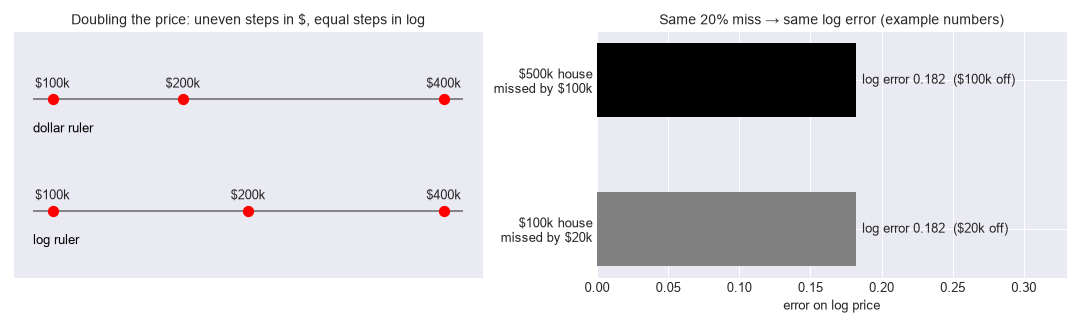

In [ ]:
target_stats = pd.DataFrame({'SalePrice':        train_raw[TARGET].describe(),
                             'log1p(SalePrice)': np.log1p(train_raw[TARGET]).describe()})
target_stats.loc['skewness'] = [skew(train_raw[TARGET]), skew(np.log1p(train_raw[TARGET]))]
display(target_stats.round(3))

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col, (name, values) in enumerate([('SalePrice ($)', train_raw[TARGET]), ('log1p(SalePrice)', np.log1p(train_raw[TARGET]))]):
    sns.histplot(values, bins=50, kde=True, color=PALETTE['main'], ax=axes[0, col])
    axes[0, col].set_title(f'{name} · skewness {skew(values):.2f}')
    qq_plot(values, axes[1, col], f'Q-Q plot · {name}')
plt.tight_layout()
plt.show()

# [4/11] Simple linear regression

**What I'm trying to do** → start as simple as possible: fit one straight line on living area, by hand and by gradient descent, and see what one extra square foot is worth.

**Question** → how much does one extra square foot of living area add to the price?

**Answer:** **\$107 per square foot**, on top of an intercept of \$18,569. My formula and scikit-learn agree to the cent, and living area alone explains 54% of the price differences (R² = 0.54 in [5/11]).

But the 4 red houses above 4,000 sq ft don't share one story: 2 sold for \$745k-755k, as the line expects, and 2 sold for only \$160k-185k.

**Simple linear regression in one line** → draw the one straight line through the cloud of houses with the smallest total squared miss.

$$\hat y = \beta_0 + \beta_1 x \qquad \text{fitted by minimising} \qquad \sum_{i=1}^{n}\big(y_i - \hat y_i\big)^2$$

**Part by part**
- $x$ → `GrLivArea`, living area above ground in sq ft; $\hat y$ → the predicted sale price, a point on the line
- $\beta_0$ → **intercept** → anchors the line: the predicted price at $x = 0$ → for a 0 sq ft house it means nothing; here \$18,569
- $\beta_1 x$ → **slope** × area → every square foot adds the same \$107, in a small house or a big one → assumes a straight-line relation (**linearity**); if prices curved upwards, one slope would be wrong at both ends
- $(y_i - \hat y_i)$ → the **residual**: how far one house sits from the line → positive = sold above the line, negative = below
- $(\dots)^2$ → squaring → big misses count far more: the typical house is missed by about \$25k and costs 1 unit; a house missed by \$463k costs 342 units → one extreme house can pull the whole line towards itself. The next answer shows 2 real houses doing exactly that
- $\sum_{i=1}^{n}$ → all 1,460 houses add their cost with the same weight → assumes the misses are independent and about the same size everywhere (**homoscedasticity**); [5/11] checks it, and it breaks on raw prices
- In short → price = a fixed start + the same amount for every square foot, like a taxi fare: a starting fee, then the same price for every extra kilometre. The line sits where the total of the squared misses is smallest

**How the slope is found, in 3 steps**
1. Find the average area $\bar x$ and the average price $\bar y$ (the red dashed lines)
2. For each house, multiply "how much bigger than average" by "how much pricier than average". Bigger *and* pricier (or smaller *and* cheaper) → positive, pushes the slope up. The others → negative, pull it down
3. Add these up and divide by how spread out the areas are → the slope. Then slide the line so it passes through the two averages → the intercept

$$\beta_1 = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2} \qquad \beta_0 = \bar y - \beta_1 \bar x$$
- $\bar x, \bar y$ → average area and average price (step 1)
- numerator → step 2: do area and price move **together**?
- denominator → how spread out the areas are (step 3)
- In short → the slope is "how much price moves together with area", turned into dollars per square foot. Here 79% of the houses push it up

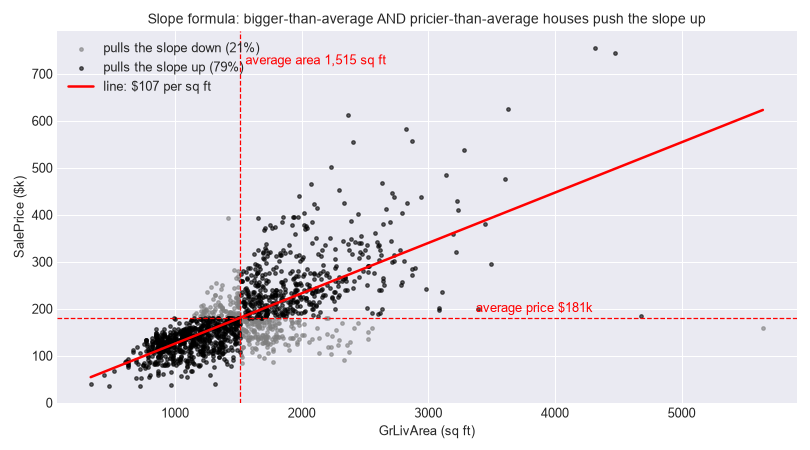

In [ ]:
def slr(x, y):
    x, y   = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    beta_1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - beta_1 * x.mean(), beta_1


beta_0, beta_1 = slr(train_raw['GrLivArea'], train_raw[TARGET])
sk_model       = LinearRegression().fit(train_raw[['GrLivArea']], train_raw[TARGET])
display(pd.DataFrame({'by formula':   [beta_0, beta_1],
                      'scikit-learn': [sk_model.intercept_, sk_model.coef_[0]]},
                     index=['β0 intercept ($)', 'β1 slope ($ per sq ft)']).round(2))

In [ ]:
giants         = train_raw['GrLivArea'] > 4000
partial_giants = giants & (train_raw['SaleCondition'] == 'Partial')
grid           = np.linspace(train_raw['GrLivArea'].min(), train_raw['GrLivArea'].max(), 100)

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(train_raw.loc[~giants, 'GrLivArea'], train_raw.loc[~giants, TARGET], s=8, alpha=0.5, color=PALETTE['soft'], label='houses')
ax.scatter(train_raw.loc[giants, 'GrLivArea'], train_raw.loc[giants, TARGET], s=60, color=PALETTE['flag'], label='> 4,000 sq ft')
ax.plot(grid, beta_0 + beta_1 * grid, color=PALETTE['main'], label=f'ŷ = {beta_0:,.0f} + {beta_1:,.1f} · x')
ax.set(xlabel='GrLivArea (sq ft)', ylabel='SalePrice ($)', title='Simple linear regression: living area → price')
ax.legend()
plt.show()

display(train_raw.loc[giants, ['Id', 'GrLivArea', 'OverallQual', 'SaleCondition', TARGET]])

**Something odd** → 2 of the 4 giants above 4,000 sq ft sold for only \$160k-185k, far below the line, while the other 2 sit right on it.

**I suspect** → these 2 are not normal sales, and the square in the loss lets them drag the line down.

**Question** → should those 2 giant houses at bargain prices stay in training?

**Answer:** No. Both are **partial sales** (`SaleCondition = Partial`: sold before construction was finished), so their price doesn't describe the finished house. The 2 genuine giants (\$745k and \$755k) stay.

**Why it matters** → removing only these 2 moves the slope from \$107 to **\$115 per sq ft** and the intercept from \$18,569 to \$7,169. 2 houses out of 1,460 bent the whole line. The dataset's author, Dean De Cock, recommends removing the houses above 4,000 sq ft for this reason.

**The square, on these 2 houses** → the line misses them by \$335k and \$463k, 13× and 18× the typical miss of \$25k. Squared, that becomes 179× and 342×: 2 houses (0.14% of the rows) carry **7.1%** of the whole $\sum (y_i - \hat y_i)^2$, so the line tilts down towards them. My suspicion was right on both points: partial sales, and a pull that comes from the square.

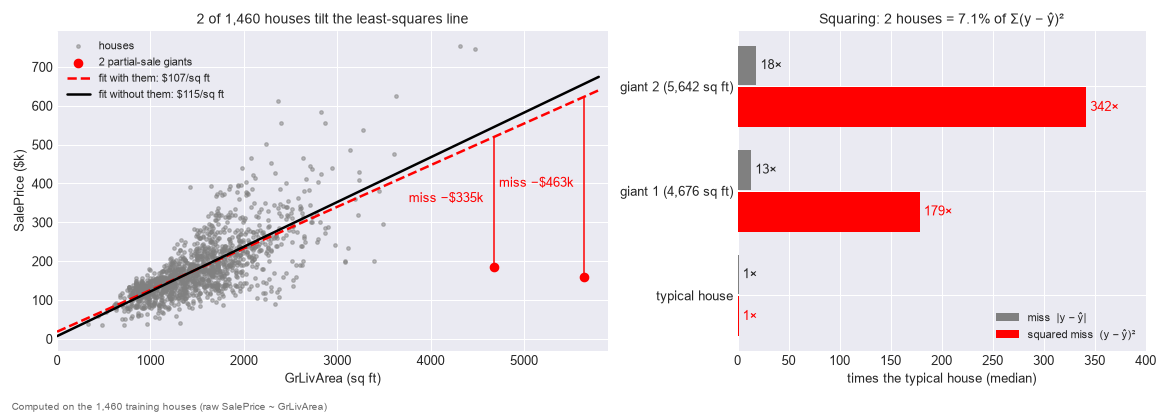

*Computed by me on the 1,460 training houses (raw price on living area), same fit as above.*

In [ ]:
train = train_raw.loc[~partial_giants].reset_index(drop=True) if DROP_PARTIAL_GIANTS else train_raw.copy()
beta_0_clean, beta_1_clean = slr(train['GrLivArea'], train[TARGET])
display(pd.DataFrame({'all houses':         [beta_0, beta_1, len(train_raw)],
                      'without 2 partials': [beta_0_clean, beta_1_clean, len(train)]},
                     index=['β0 intercept ($)', 'β1 slope ($ per sq ft)', 'houses']).round(2))

**I'm curious** → scikit-learn solved the line with one formula. How do models that have no such formula find it?

**Answer:** Same answer, different road. After 100 steps gradient descent lands on slope **0.7252** and intercept **0.0000**, the same as the closed formula to 4 decimals, with the same cost J = 0.2369. The cost stops moving after about 30 steps. On standardised data the slope is simply the correlation between area and log price: 0.73.

**Gradient descent in one line** → start with any line, find the small change that makes the miss smaller, make it, repeat.

**How it works, in 4 steps**
1. **Standardise** → rescale area and log price to mean 0, std 1, so one step size suits both the slope and the intercept
2. **Start** → slope 0, intercept 0: a flat line
3. **Gradient** → for every house, check how far off the line is and in which direction, and average that into "tilt the line up or down, lift it or lower it"
4. **Step** → move slope and intercept a little the other way (learning rate 0.1), then back to step 3. 100 times

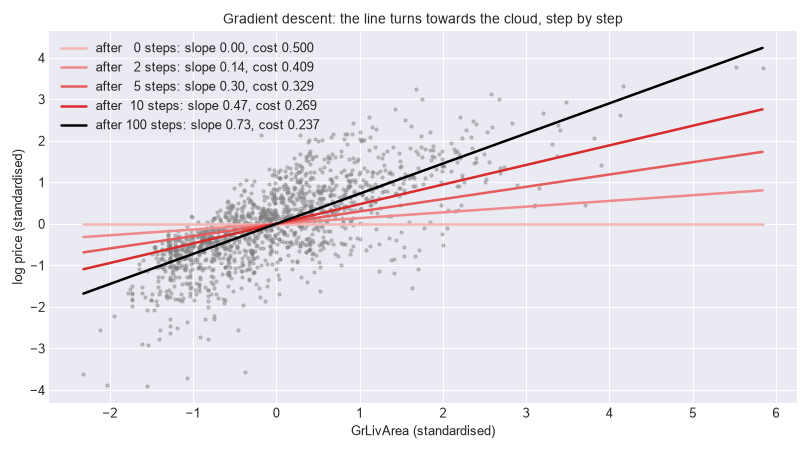

$$J(w, b) = \frac{1}{2n}\sum_{i=1}^{n}\big(w x_i + b - y_i\big)^2$$
- $w, b$ → slope and intercept being searched for
- $J$ → **cost**: half the average squared miss. Over all $(w, b)$ pairs it forms a bowl
- In short → J is one number that says how bad the current line is; the best line sits at the bottom of the bowl

$$w \leftarrow w - \eta\,\frac{\partial J}{\partial w} \qquad b \leftarrow b - \eta\,\frac{\partial J}{\partial b}$$
- $\frac{\partial J}{\partial w}, \frac{\partial J}{\partial b}$ → **gradient**: the direction in which the miss grows fastest (step 3)
- $\eta$ → **learning rate**: the step size (step 4)
- In short → walk downhill in thick fog: feel which way the ground slopes under your feet, take a small step the other way, repeat. Too-big steps overshoot the valley, too-small ones take all day

The figure after the next cell shows the same walk from above, on the bowl.

In [ ]:
def gradient_descent(x, y, lr=0.1, steps=100):
    w, b, path = 0.0, 0.0, []
    for _ in range(steps):
        error = w * x + b - y
        path.append((w, b, np.mean(error ** 2) / 2))
        w    -= lr * np.mean(error * x)
        b    -= lr * np.mean(error)
    return w, b, np.array(path)


x_std          = ((train['GrLivArea'] - train['GrLivArea'].mean()) / train['GrLivArea'].std()).to_numpy()
y_std          = ((np.log1p(train[TARGET]) - np.log1p(train[TARGET]).mean()) / np.log1p(train[TARGET]).std()).to_numpy()
w_gd, b_gd, gd_path = gradient_descent(x_std, y_std)
b_ls, w_ls     = slr(x_std, y_std)
display(pd.DataFrame({'gradient descent (100 steps)': [w_gd, b_gd, gd_path[-1, 2]],
                      'closed formula':               [w_ls, b_ls, np.mean((w_ls * x_std + b_ls - y_std) ** 2) / 2]},
                     index=['w slope', 'b intercept', 'cost J']).round(4))

In [ ]:
W, B = np.meshgrid(np.linspace(-0.25, 1.25, 80), np.linspace(-0.75, 0.75, 80))
J    = ((W[..., None] * x_std + B[..., None] - y_std) ** 2).mean(axis=-1) / 2

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
contour = axes[0].contour(W, B, J, levels=15, colors=PALETTE['soft'], linewidths=1)
axes[0].clabel(contour, fontsize=8)
axes[0].plot(gd_path[:, 0], gd_path[:, 1], marker='o', markersize=3, color=PALETTE['flag'], label='gradient descent path')
axes[0].scatter([w_ls], [b_ls], marker='*', s=250, color=PALETTE['main'], zorder=3, label='closed-formula answer')
axes[0].set(xlabel='w (slope)', ylabel='b (intercept)', title='Cost surface J(w, b): walking downhill')
axes[0].legend()
axes[1].plot(gd_path[:, 2], color=PALETTE['main'])
axes[1].set(xlabel='step', ylabel='cost J', title='Cost per step')
plt.tight_layout()
plt.show()

# [5/11] Assumptions

**Clue** → 2 houses out of 1,460 bent the line from \$107 to \$115 per sq ft, and the loss behind it gives every house the same weight.

**I suspect** → the misses are not the same size for cheap and expensive houses, so "every house counts the same" doesn't hold here.

**Question** → which of the 5 textbook assumptions break?

**Let's break it down** → 1) do area and price rise in one straight band? 2) do the misses fan out as prices rise (Breusch-Pagan)? 3) do the misses follow a bell curve? 4) do the features repeat each other (VIF)?

Linear regression gives honest coefficients only if 5 assumptions hold:

| # | Assumption | In plain words |
|---|---|---|
| 1 | Linearity | price rises in a straight line with each feature |
| 2 | Independence | one house's miss tells nothing about another's |
| 3 | Homoscedasticity | misses are about the same size for cheap and expensive houses |
| 4 | Normality | misses follow a bell curve (needed for trustworthy p-values and intervals) |
| 5 | No multicollinearity | features don't repeat each other (next question) |

**Answer (1-4):**
- **Linearity** → holds well enough: area and price rise together in one straight band, and log price costs almost no fit (R² 0.54 → 0.53)
- **Independence** → each row is a separate sale, not a time series, so there is no order through which misses could leak into each other
- **Homoscedasticity** → broken on raw prices: the misses fan out like a funnel as prices rise (Breusch-Pagan LM = 249). On log price the funnel becomes an even band, LM = 23, about 11× smaller (still significant with a single feature)
- **Normality** → raw residuals skew right (0.80): the line under-prices expensive houses. Log residuals are close to the bell curve except a left tail (−0.55) of cheap houses priced too high; they come back in [10/11]

→ I was right about the size of the misses: on raw prices they fan out, and the log from [3/11] fixes most of it. From here on every model predicts log price.

**Residual in one line** → what the line got wrong for one house: real price minus predicted price.

$$e_i = y_i - \hat y_i$$
- $e_i$ → residual of house $i$: above the line → positive, below → negative
- In short → the red sticks in the picture. A good model leaves short sticks that look random, not sticks that grow as the price goes up

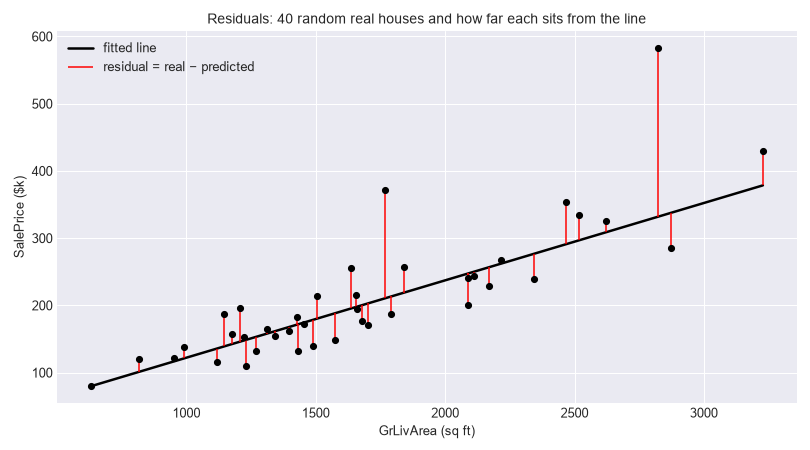

**Breusch-Pagan test in one line** → check whether the features can predict how *big* the miss is. If they can, the misses are not the same size everywhere.

**How it works, in 4 steps**
1. Fit the line and get every residual $e_i$
2. Square them → $e_i^2$ = how big the miss is, without the sign
3. Fit a small regression of $e_i^2$ on the features (the red line in the picture)
4. LM = number of houses × R² of that small regression. A large LM (p-value below 0.05) → the size of the miss depends on the features = **heteroscedasticity**

$$\text{LM} = n \cdot R^2_{e^2}$$
- $n$ → number of houses (1,458)
- $R^2_{e^2}$ → how well the features predict the squared residuals (step 3)
- In short → if bigger houses get bigger misses, the small regression finds it and LM goes up: 249 on raw price, 23 on log price

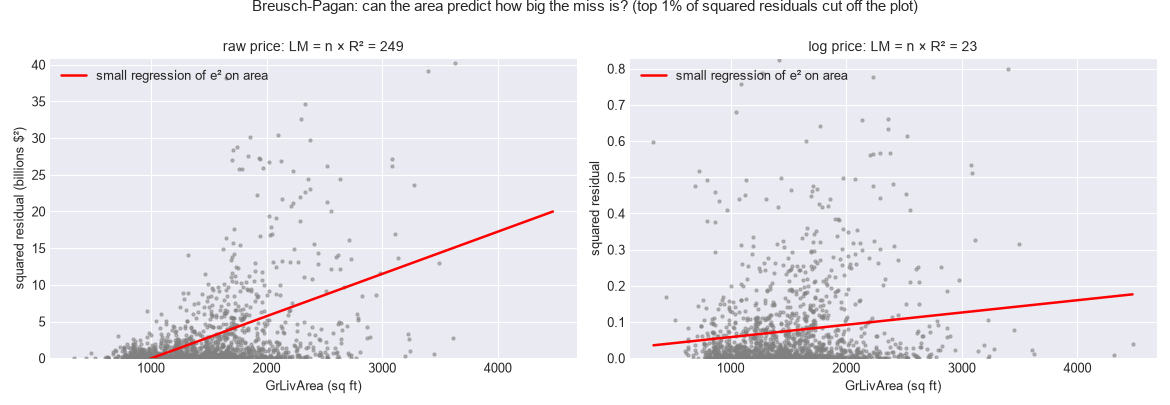

In [ ]:
fits = {'SalePrice':        train[TARGET].to_numpy(dtype=float),
        'log1p(SalePrice)': np.log1p(train[TARGET]).to_numpy()}
X_one = train[['GrLivArea']].to_numpy(dtype=float)
rows  = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, (name, target) in enumerate(fits.items()):
    model  = LinearRegression().fit(X_one, target)
    fitted = model.predict(X_one)
    resid  = target - fitted
    rows[name] = {'R²':                model.score(X_one, target),
                  'residual skewness': skew(resid),
                  'Breusch-Pagan LM':  het_breuschpagan(resid, add_constant(X_one))[0],
                  'Breusch-Pagan p':   het_breuschpagan(resid, add_constant(X_one))[1]}
    axes[0, col].scatter(fitted, resid, s=8, alpha=0.5, color=PALETTE['main'])
    axes[0, col].axhline(0, color=PALETTE['flag'])
    axes[0, col].set(title=f'Residuals vs fitted · {name}', xlabel='fitted', ylabel='residual')
    qq_plot(resid, axes[1, col], f'Q-Q plot of residuals · {name}')
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).T.round(4))

**I'm curious** → `GarageCars` and `GarageArea` both measure the garage, `GrLivArea` and `TotRmsAbvGrd` both measure size.

**Question** → do the strongest features repeat each other (assumption 5)?

**Answer:** Some overlap, nothing severe. The highest VIF is **5.4** (`GarageCars`), then `GrLivArea` 5.0 and `GarageArea` 5.0:
- garage size is counted twice, once in cars and once in square feet (correlation 0.88)
- living area overlaps with the room count (0.83)

No VIF passes 10, but with all 79 columns and almost 200 one-hot categories the small overlaps add up → instead of dropping columns by hand, I let Ridge and Lasso share or remove the credit in [8/11].

**VIF in one line** → try to predict one feature from all the others; the better that works, the more the feature just repeats them.

**How it works**
1. Pick one feature, e.g. `GarageCars`
2. Fit a regression that predicts it from the other 9 features → its $R_j^2$
3. Turn that into a VIF with the formula below, and repeat for every feature

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
- $R_j^2$ → how well feature $j$ is predicted by **all the other** features (step 2)
- $\text{VIF}_j$ → **variance inflation factor**: how many times wider the uncertainty of $\beta_j$ gets because of the overlap. 1 = independent, above 5 = worrying, above 10 = severe
- In short → when two features tell the same story, the regression can't decide which one gets the credit, so both coefficients get shaky. `GarageCars` is about 82% predictable from the others → VIF 5.4

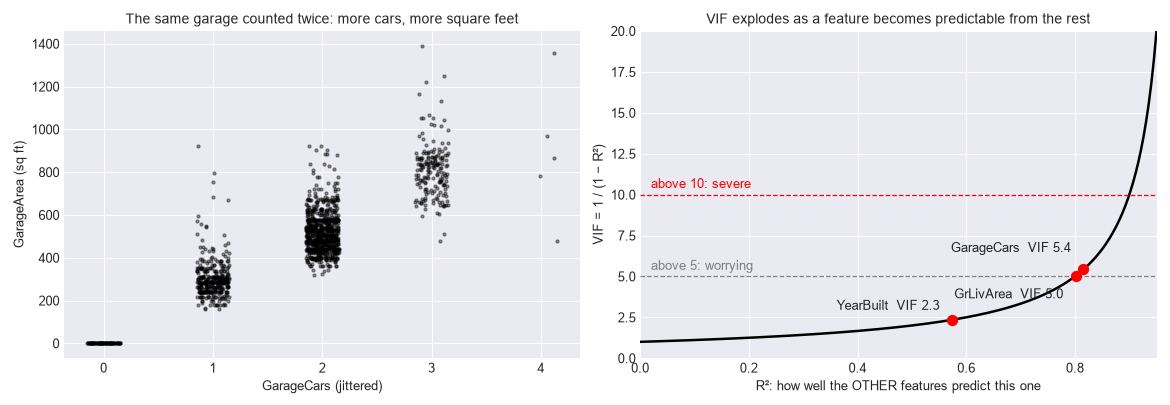

In [ ]:
vif_cols = ['OverallQual', 'GrLivArea', 'TotRmsAbvGrd', 'GarageCars', 'GarageArea',
            'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt', 'YearRemodAdd']
vif_X    = add_constant(train[vif_cols].fillna(0).astype(float))
vif      = pd.DataFrame({'VIF': [variance_inflation_factor(vif_X.values, i) for i in range(1, vif_X.shape[1])]}, index=vif_cols)
display(vif.sort_values('VIF', ascending=False).round(2))

# [6/11] Features

**Aim** → turn text into numbers the right way and tame the skewed columns: ordinal scales → numbers, categories → 0/1 columns, skewed areas → log1p.

**Question:** A regression multiplies every column by one $\beta$. What does that mean for text columns?

**Answer:** It depends on whether the text has an order:

| Kind | Example | Becomes | Why |
|---|---|---|---|
| Ordinal (has an order) | `ExterQual`: Ex > Gd > TA > Fa > Po | 5 … 1, absent = 0 | each step up adds about the same |
| Nominal (no order) | `Neighborhood`, `MSZoning` | one 0/1 column per category (one-hot) | each category gets its own $\beta$ |
| Skewed number | `LotArea`, porch areas | $\log(1 + x)$, then standardised | a few huge values would steer the line, like the 2 giant houses did |

Result: 55 numeric columns (31 of them log-transformed because |skewness| > 0.75) and 34 categorical columns that become 194 one-hot columns → a model matrix of **1,458 houses × 249 columns**.

**Does the data agree?** Yes:
- `ExterQual` → median price \$82k → \$139k → \$220k → \$369k from Fair to Excellent: each step multiplies the price by about 1.6-1.7, i.e. **equal steps on the log scale**, exactly what one $\beta$ per step on log price assumes
- `Neighborhood` → 25 neighbourhoods jump unevenly from \$88,000 (MeadowV) to \$315,000 (NridgHt), with no order in their names → one $\beta$ each

**Ordinal encoding in one line** → replace each quality word by its rank.

$$\hat y = \dots + \beta_{\text{qual}} \cdot \text{quality}$$
- quality → 5 for Ex, 4 Gd, 3 TA, 2 Fa, 1 Po, and 0 when the house doesn't have the thing (no pool, no garage)
- $\beta_{\text{qual}}$ → one number for the whole scale
- In short → one $\beta$ means every step up the scale adds the **same** amount to log price, like hotel stars where each extra star costs about the same premium

**One-hot encoding in one line** → one yes/no column per category, so each category gets its own price effect.

**How it works**
1. List the categories of the column (25 neighbourhoods)
2. Make one column per category: 1 if the house is in it, 0 if not
3. Merge categories with fewer than 10 houses into one "infrequent" column, so no $\beta$ is learnt from 2 houses

$$\hat y = \dots + \beta_{\text{NridgHt}} \cdot [\text{Neighborhood} = \text{NridgHt}] + \beta_{\text{OldTown}} \cdot [\text{Neighborhood} = \text{OldTown}] + \dots$$
- $[\text{Neighborhood} = \text{NridgHt}]$ → 1 if the house is in NridgHt, else 0
- $\beta_{\text{NridgHt}}$ → the price effect of being in NridgHt
- In short → each neighbourhood gets its own price bump. Numbering them 1, 2, 3 (label encoding) would force equal, ordered steps between places that have no order
- `MSSubClass` is a building-type **code** stored as numbers → one-hot too

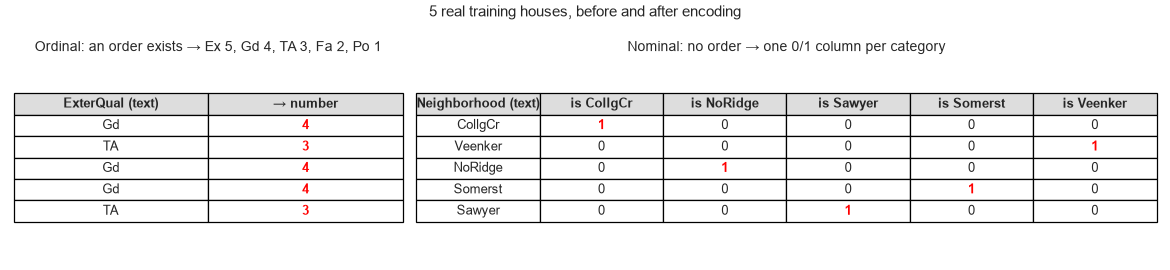

**Skew + log1p in one line** → if a column has a long tail of huge values, squeeze it with $\log(1 + x)$, just like the price.

**How it works**
1. **Skewness** → one number for how lopsided a column is: 0 = symmetric, large and positive = a long tail to the right
2. If |skewness| > `SKEW_LIMIT` (0.75) and the column has no negative values → replace $x$ by $\log(1 + x)$. The "+1" keeps 0 sq ft (no porch) at 0
3. Standardise every numeric column (mean 0, std 1), so the penalty in [8/11] treats square feet and bathroom counts the same
4. All of it is measured inside each training fold, never on validation rows

$$\text{skewness} = \frac{\frac1n\sum_i (x_i - \bar x)^3}{\big(\frac1n\sum_i (x_i - \bar x)^2\big)^{3/2}}$$
- $(x_i - \bar x)^3$ → the cube keeps the sign, and makes far-away values count a lot
- denominator → the spread, cubed, so the result has no unit
- In short → skewness says how far one side of the histogram stretches out. `LotArea` has 12.6; after log1p it is −0.18

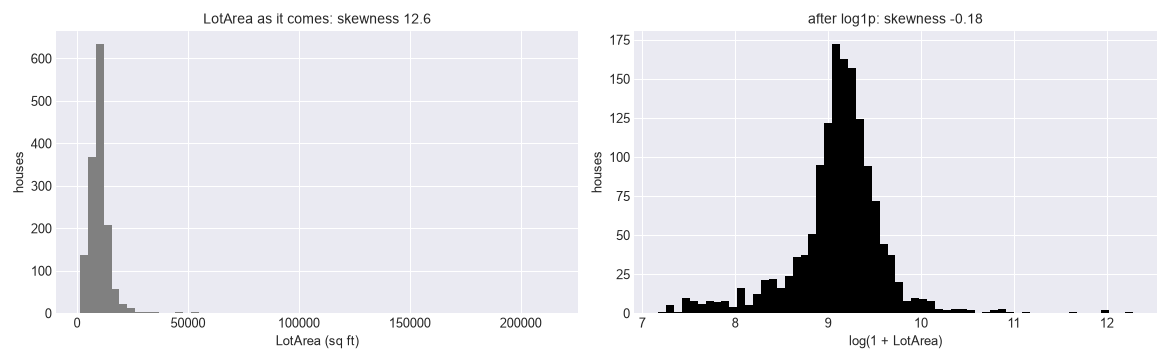

In [ ]:
qual_price  = (train.assign(level=train['ExterQual'].map(QUALITY_SCALE))
               .groupby('level')[TARGET].agg(['median', 'size']))
neigh_price = train.groupby('Neighborhood')[TARGET].agg(['median', 'size']).sort_values('median')

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1, 3]})
axes[0].bar(qual_price.index.astype(str), qual_price['median'], color=PALETTE['main'])
axes[0].set(title='ExterQual: ordered steps', xlabel='quality level (2 = Fa … 5 = Ex)', ylabel='median SalePrice ($)')
axes[1].bar(neigh_price.index, neigh_price['median'], color=PALETTE['soft'])
axes[1].tick_params(axis='x', rotation=60)
axes[1].set(title='Neighborhood: no natural order, uneven gaps', ylabel='median SalePrice ($)')
plt.tight_layout()
plt.show()

**Question:** Which new features can I build from the existing columns, and do they help?

**Answer:** Yes. `TotalSF` becomes the strongest single feature in the data: correlation **0.83** with log price, against 0.73 for `GrLivArea` and 0.65 for `TotalBsmtSF` (correlation → from −1 to 1, how closely two columns move together in a straight line).

| Feature | Built from | Why |
|---|---|---|
| `TotalSF` | basement + 1st + 2nd floor | buyers pay for total space, not per floor |
| `TotalBath` | full + ½ half baths, above ground and basement | one "bathroom count" instead of 4 overlapping ones |
| `TotalPorchSF` | open, enclosed, 3-season, screen porch, wood deck | 5 sparse columns → 1 dense one |
| `HouseAge`, `RemodAge` | `YrSold − YearBuilt`, `YrSold − YearRemodAdd` | age **at sale**, not years before an arbitrary date |
| `Has…` flags | pool, 2nd floor, garage, basement, fireplace | 0 sq ft means "none", not "very small" |

**The others**
- `TotalBath` (0.68) beats `FullBath` (0.60), and `TotalPorchSF` (0.40) beats the best single porch column (0.33)
- the ages mirror their year columns (−0.59 vs 0.59): the same information, read as years of age at the sale
- the `Has…` flags are weak on their own (0.08-0.51); they mainly let the linear model tell "none" apart from "small"

In [ ]:
def prepare(df):
    out = df.drop(columns=['Id', TARGET], errors='ignore').copy()
    for col in ABSENT_MEANS_NONE:
        out[col] = out[col].fillna('None')
    for col in QUALITY_COLS:
        out[col] = out[col].map(QUALITY_SCALE).fillna(0)
    out['MSSubClass']   = out['MSSubClass'].astype(str)
    out['GarageYrBlt']  = out['GarageYrBlt'].fillna(out['YearBuilt'])
    out['TotalSF']      = out['TotalBsmtSF'].fillna(0) + out['1stFlrSF'] + out['2ndFlrSF']
    out['TotalBath']    = (out['FullBath'] + 0.5 * out['HalfBath']
                           + out['BsmtFullBath'].fillna(0) + 0.5 * out['BsmtHalfBath'].fillna(0))
    out['TotalPorchSF'] = out[['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']].sum(axis=1)
    out['HouseAge']     = out['YrSold'] - out['YearBuilt']
    out['RemodAge']     = out['YrSold'] - out['YearRemodAdd']
    out['HasPool']      = (out['PoolArea'] > 0).astype(int)
    out['Has2ndFlr']    = (out['2ndFlrSF'] > 0).astype(int)
    out['HasGarage']    = (out['GarageArea'].fillna(0) > 0).astype(int)
    out['HasBsmt']      = (out['TotalBsmtSF'].fillna(0) > 0).astype(int)
    out['HasFireplace'] = (out['Fireplaces'] > 0).astype(int)
    return out


X_all    = prepare(train)
X_test   = prepare(test_raw)
y_log    = np.log1p(train[TARGET]).to_numpy()
num_cols = [col for col in X_all.columns if pd.api.types.is_numeric_dtype(X_all[col])]
cat_cols = [col for col in X_all.columns if col not in num_cols]
show_block('Outputs', {'X_all':                X_all.shape,
                       'X_test':               X_test.shape,
                       'numeric columns':      len(num_cols),
                       'categorical columns':  len(cat_cols)})

In [ ]:
engineered = ['TotalSF', 'TotalBath', 'TotalPorchSF', 'HouseAge', 'RemodAge',
              'HasPool', 'Has2ndFlr', 'HasGarage', 'HasBsmt', 'HasFireplace']
originals  = ['GrLivArea', 'TotalBsmtSF', 'FullBath', 'OpenPorchSF', 'YearBuilt', 'YearRemodAdd']
corr       = X_all[engineered + originals].corrwith(pd.Series(y_log)).rename('corr with log price').to_frame()
corr['type'] = np.where(corr.index.isin(engineered), 'engineered', 'original')
display(corr.sort_values('corr with log price', key=np.abs, ascending=False).round(3))

In [ ]:
class SkewLog1p(BaseEstimator, TransformerMixin):
    def __init__(self, limit=SKEW_LIMIT):
        self.limit = limit

    def fit(self, X, y=None):
        X          = np.asarray(X, dtype=float)
        self.mask_ = (np.abs(np.nan_to_num(skew(X, axis=0))) > self.limit) & (X.min(axis=0) >= 0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        X[:, self.mask_] = np.log1p(X[:, self.mask_])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def make_preprocessor():
    numeric     = make_pipeline(SimpleImputer(strategy='median'), SkewLog1p(), StandardScaler())
    categorical = make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),
                                OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=MIN_CATEGORY_COUNT,
                                              sparse_output=False))
    return ColumnTransformer([('num', numeric, num_cols), ('cat', categorical, cat_cols)], verbose_feature_names_out=False)


preview_prep = make_preprocessor().fit(X_all)
log_columns  = [col for col, flag in zip(num_cols, preview_prep.named_transformers_['num'][1].mask_) if flag]
show_block('Outputs', {'model matrix (all train)': preview_prep.transform(X_all).shape,
                       'numeric columns logged':   len(log_columns),
                       'one-hot columns':          len(preview_prep.named_transformers_['cat'][1].get_feature_names_out())})

# [7/11] Multiple linear regression

**Clue** → living area alone explains 54% of the price differences, and [6/11] built a matrix of 249 columns, with `TotalSF` even stronger than living area (0.83).

**I'm curious** → how much of the other 46% the rest of the columns can explain.

**I suspect** → it won't be free: [5/11] found size and garage columns overlapping (VIF up to 5.4), and 194 one-hot columns add more overlap.

**Let's break it down** → 1) score the average guess, area only and all features on the same 5 folds 2) compare the average error **and** the spread between folds 3) look at the worst-priced houses

**Question** → how much better than one feature is a regression on all of them?

**Answer:** Much better on 4 of the 5 folds, and a disaster on the 5th:

| Model | Result |
|---|---|
| always guess the average | typical miss 49% |
| area only | typical miss 32% |
| all features, folds 1-4 | RMSE 0.12-0.13, typical miss about **13%** |
| all features, fold 5 | RMSE 0.54 |

On fold 5 plain least squares priced a \$274,970 house at **\$187,858,413** and a \$250,000 house at **\$689**. The average (0.208) looks acceptable, but the fold spread (0.164) says this model can't be trusted.

**Why it breaks** → 249 overlapping columns. A few rare category combinations get extreme coefficients that cost nothing in training and explode on one unseen house. My suspicion was right, and worse than I expected: "no VIF above 10" in [5/11] did not mean safe once all 249 columns were in.

**Multiple linear regression in one line** → the same straight-line idea, but with one slope per column, all fitted together.

$$\hat y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p \qquad \hat\beta = (X^\top X)^{-1} X^\top y$$
**Part by part**
- $x_1 \dots x_p$ → the $p$ prepared columns of one house; $X$ → all houses stacked as rows
- $\beta_0$ → the starting log price every house shares before any column adds its part
- $\beta_j x_j$ → one column times its own slope → moves log price by a fixed amount, whatever the other columns say → on log price, $e^{\beta_j} - 1$ is a fixed **percent** change → assumes effects don't depend on each other: a square foot is worth the same in NridgHt and in MeadowV (no interactions, see Next steps)
- $+ \dots +$ → the sum → the columns' effects simply add up → that is why each $\beta_j$ reads "with **every other column fixed**"
- $(X^\top X)^{-1}$ → solves for all $\beta$s at once and undoes the overlap between columns → when columns nearly repeat each other it divides by nearly zero and the $\beta$s explode: the \$187,858,413 house on fold 5
- $\hat\beta$ → still the line with the smallest $\sum (y_i - \hat y_i)^2$, as in [4/11] → the worst-fitting houses still pull hardest
- In short → the price is a sum: each column times its own slope, added up. "Every other column fixed" is the key. In the picture (a small 2-feature model, just to show the idea) every quality level gets the same slope for area, only shifted up by about 19% per quality step

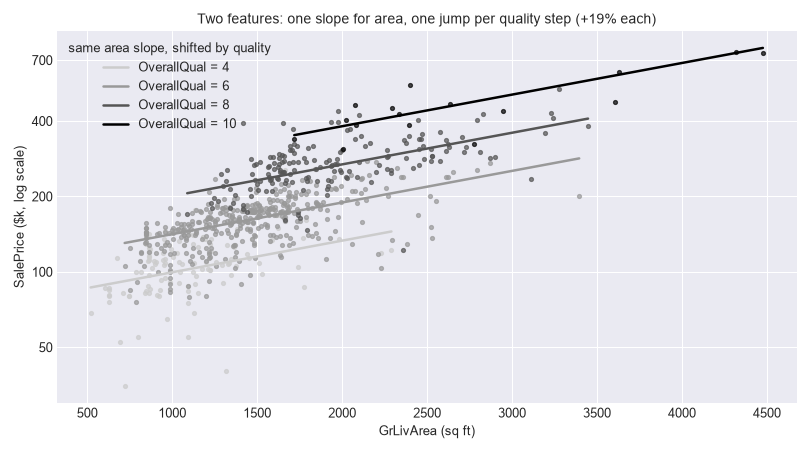

**Cross-validation in one line** → score every model on houses it has never seen, 5 times, so every house is scored once.

**How it works, in 4 steps**
1. Shuffle the 1,458 houses and cut them into 5 groups (folds) of about 291
2. Train on 4 groups, score the 5th
3. Rotate until every group has been scored once
4. Report the average RMSE of the 5 rounds, and the spread (std) between them: a big spread = an unstable model

Every fitted step (fill values, skew check, scaling, encoding) is refit inside each round, so the scored houses never leak into training.

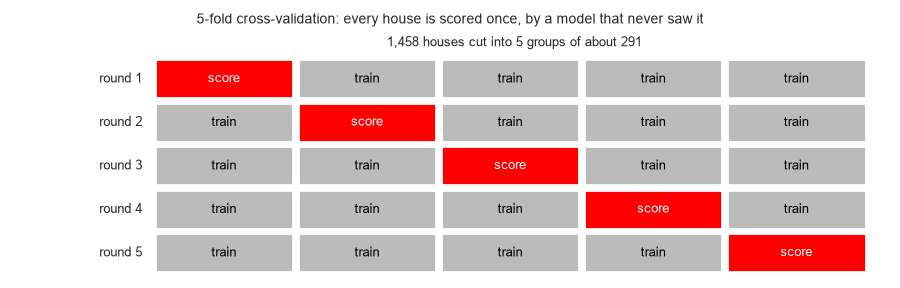

In [ ]:
folds       = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results     = {}
oof_preds   = {}
fold_scores = {}


def cv_rmse(model, X=X_all, y=y_log):
    oof       = cross_val_predict(model, X, y, cv=folds)
    fold_rmse = [rmse(y[val], oof[val]) for _, val in folds.split(X)]
    return fold_rmse, oof


def evaluate(name, model):
    fold_rmse, oof    = cv_rmse(model)
    mean              = float(np.mean(fold_rmse))
    results[name]     = {'CV RMSE (log)': mean, 'fold std': float(np.std(fold_rmse)), 'typical miss %': (np.exp(mean) - 1) * 100}
    oof_preds[name]   = oof
    fold_scores[name] = fold_rmse
    return oof

In [ ]:
first_models = {
    'Baseline (average price)': DummyRegressor(),
    'SLR (GrLivArea)':          make_pipeline(ColumnTransformer([('x', 'passthrough', ['GrLivArea'])]), LinearRegression()),
    'MLR (all features)':       make_pipeline(make_preprocessor(), LinearRegression()),
}
for i, (name, model) in enumerate(first_models.items(), 1):
    print(f'[{i}/{len(first_models)}] {name}')
    evaluate(name, model)
display(pd.DataFrame(results).T.round(4))

In [ ]:
mlr_full  = make_pipeline(make_preprocessor(), LinearRegression()).fit(X_all, y_log)
mlr_coefs = pd.Series(mlr_full[-1].coef_, index=mlr_full[0].get_feature_names_out())
show_block('Outputs', {'coefficients':            len(mlr_coefs),
                       'largest |β|':             f'{mlr_coefs.abs().max():,.2f}',
                       'median |β|':              f'{mlr_coefs.abs().median():,.4f}'})
display(pd.DataFrame(fold_scores, index=[f'fold {i}' for i in range(1, N_FOLDS + 1)]).T.round(4))

In [ ]:
mlr_miss  = np.abs(oof_preds['MLR (all features)'] - y_log)
worst     = train.loc[mlr_miss.argsort()[::-1][:3], ['Id', 'GrLivArea', 'Neighborhood', 'SaleCondition', TARGET]]
worst['MLR predicted $'] = np.expm1(oof_preds['MLR (all features)'][worst.index]).round(0)
display(worst)

# [8/11] Ridge and Lasso

**Clue** → on fold 5 plain least squares priced a \$274,970 house at \$187,858,413, because overlapping columns let a few coefficients grow huge.

**Aim** → stop the coefficients from exploding: add a penalty on big coefficients and tune its strength by cross-validation.

**Question** → can a penalty on large coefficients calm the overlapping columns down?

**Answer:** Yes. Cross-validated RMSE drops from 0.208 (plain MLR) to **0.113** (Ridge, α ≈ 14.7) and **0.112** (Lasso, α ≈ 0.00056), a typical miss of about 12%. The fold spread falls from 0.164 to below 0.007: no more exploding houses.

**What to look for in the curves below** → each one has a clear valley. Too little penalty lets the noise back in, too much flattens real effects; the valley between them is the bias-variance trade-off made visible.

**Regularisation in one line** → make big coefficients cost something, so the model only uses a big $\beta$ when it really pays off.

**How it works, in 4 steps**
1. Standardise every column, so the penalty treats square feet and bathroom counts the same
2. Add a penalty to the usual squared misses: Ridge adds the squared size of every $\beta$, Lasso adds the plain size
3. Try 25 penalty strengths α and score each with the same 5 folds
4. Keep the α with the lowest cross-validated RMSE

$$\text{Ridge:}\quad \min_\beta \sum_{i}(y_i - \hat y_i)^2 + \alpha \sum_{j}\beta_j^2 \qquad\qquad \text{Lasso:}\quad \min_\beta \frac{1}{2n}\sum_{i}(y_i - \hat y_i)^2 + \alpha \sum_{j}|\beta_j|$$
**Part by part**
- $\sum_i (y_i - \hat y_i)^2$ → the usual squared misses → on its own it pulls the $\beta$s to the best training fit, exploding ones included
- $+$ → the trade → every bit of training fit must now be paid for with smaller coefficients
- $\alpha$ → **penalty strength**, the price of a big $\beta$ → 0 = plain least squares (fold 5 again), large = every $\beta$ pushed towards 0 and real effects forgotten → the valley in the curves below is the best price
- $\sum_j \beta_j^2$ (Ridge, **L2**) → squares each coefficient → big coefficients cost a lot, small ones almost nothing → all shrink, none reach 0, and two overlapping columns (e.g. `GarageCars` and `GarageArea`) share the credit instead of one going hugely up and the other hugely down
- $\sum_j |\beta_j|$ (Lasso, **L1**) → every unit costs the same, however small the coefficient → a weak column isn't worth its cost and lands on **exactly 0** = built-in feature selection (100 of 249 kept, next answer)
- the $\sum_j$ part → leaves the intercept out and adds up all columns on one scale → that's why every column is standardised first (step 1); otherwise square feet and bathroom counts would be penalised differently just because of their units
- $\frac{1}{2n}$ in Lasso → only scikit-learn's scaling of the first term → the two best α values (14.7 and 0.00056) can't be compared with each other
- In short → both give up a little training fit for steadier coefficients. Ridge shrinks every $\beta$ a bit; Lasso drops the weak ones completely. In the picture, as α grows, Ridge's lines all slide smoothly towards 0, while Lasso's hit 0 one by one

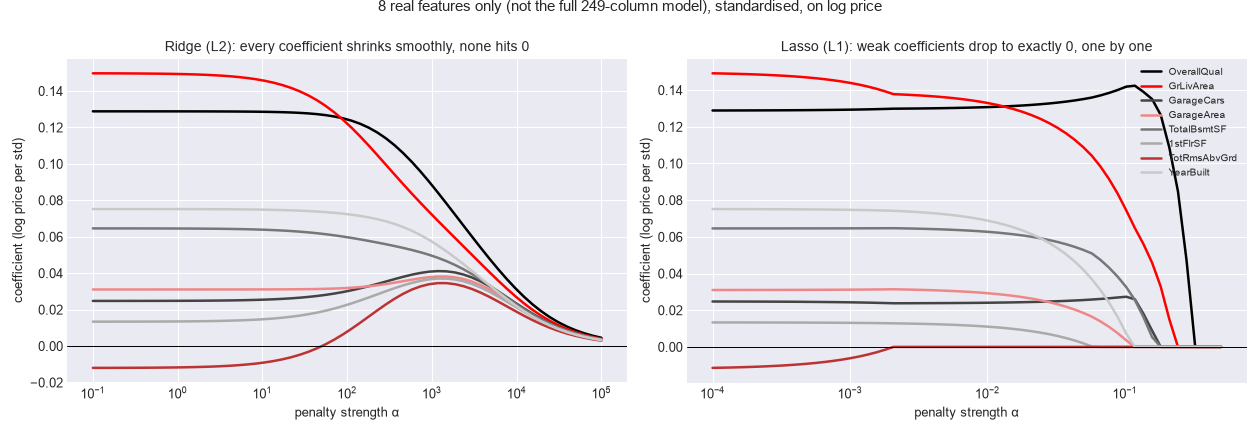

In [ ]:
def alpha_curve(estimator, grid):
    scores = []
    for i, alpha in enumerate(grid, 1):
        fold_rmse, _ = cv_rmse(make_pipeline(make_preprocessor(), clone(estimator).set_params(alpha=alpha)))
        scores.append(np.mean(fold_rmse))
    return np.array(scores)


ridge_grid   = np.logspace(*RIDGE_ALPHAS)
lasso_grid   = np.logspace(*LASSO_ALPHAS)
print(f'[1/2] Ridge · {len(ridge_grid)} alphas × {N_FOLDS} folds')
ridge_scores = alpha_curve(Ridge(), ridge_grid)
print(f'[2/2] Lasso · {len(lasso_grid)} alphas × {N_FOLDS} folds')
lasso_scores = alpha_curve(Lasso(max_iter=50000), lasso_grid)
best_ridge   = ridge_grid[np.argmin(ridge_scores)]
best_lasso   = lasso_grid[np.argmin(lasso_scores)]
show_block('Outputs', {'best Ridge alpha': f'{best_ridge:.4g}', 'best Lasso alpha': f'{best_lasso:.4g}'})

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, name, grid, scores, best in [(axes[0], 'Ridge', ridge_grid, ridge_scores, best_ridge),
                                      (axes[1], 'Lasso', lasso_grid, lasso_scores, best_lasso)]:
    ax.semilogx(grid, scores, marker='o', markersize=4, color=PALETTE['main'])
    ax.axvline(best, color=PALETTE['flag'], linestyle='--', label=f'best α = {best:.3g}')
    ax.axhline(results['MLR (all features)']['CV RMSE (log)'], color=PALETTE['soft'], linestyle=':', label='plain MLR')
    ax.set(xlabel='α (log scale)', ylabel='CV RMSE (log price)', title=f'{name}: error vs penalty strength')
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
RIDGE_NAME = f'Ridge (α = {best_ridge:.3g})'
LASSO_NAME = f'Lasso (α = {best_lasso:.3g})'
evaluate(RIDGE_NAME, make_pipeline(make_preprocessor(), Ridge(alpha=best_ridge)))
evaluate(LASSO_NAME, make_pipeline(make_preprocessor(), Lasso(alpha=best_lasso, max_iter=50000)))
display(pd.DataFrame(results).T.round(4))

**I'm curious** → Lasso can set a coefficient to exactly 0. Which features does it keep, and what is each worth?

**Answer:** Lasso keeps **100 of 249** columns and sets 149 to exactly zero. The strongest effects make real-estate sense:
- **Zoning** → commercial zoning (`MSZoning = C (all)`) cuts the price by about 24%
- **Location** → Crawford +10%, Stone Brook +9%, Northridge Heights +5% relative to the other neighbourhoods
- **Size and quality** → one standard deviation more living area +9%, overall quality +7%, total area +5%
- **Sale** → new houses +7%, abnormal sales (foreclosures, short sales) −3.5%
- **Age** → one standard deviation older −4%

**How to read a coefficient**
- numeric column → columns are standardised, so it reads "**one standard deviation more** of this feature changes the price by $e^{\beta} - 1$"
- one-hot column → "being in this category vs the reference"
- every effect is "all else equal": `GrLivArea` and `TotalSF` share the credit for size, so each looks smaller than size as a whole

In [ ]:
lasso_full  = make_pipeline(make_preprocessor(), Lasso(alpha=best_lasso, max_iter=50000)).fit(X_all, y_log)
lasso_coefs = pd.Series(lasso_full[-1].coef_, index=lasso_full[0].get_feature_names_out())
top_coefs   = lasso_coefs[lasso_coefs != 0].sort_values(key=np.abs, ascending=False).head(20)
show_block('Outputs', {'columns in': len(lasso_coefs), 'kept (β ≠ 0)': int((lasso_coefs != 0).sum()),
                       'dropped (β = 0)': int((lasso_coefs == 0).sum())})
display(pd.DataFrame({'β (log price)': top_coefs, 'price effect %': (np.exp(top_coefs) - 1) * 100}).round(3))

In [ ]:
plot_coefs = top_coefs.sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_coefs.index, (np.exp(plot_coefs) - 1) * 100,
        color=[PALETTE['flag'] if value < 0 else PALETTE['main'] for value in plot_coefs])
ax.set(xlabel='price effect (%)', title='Lasso: 20 strongest features')
plt.show()

# [9/11] Benchmark

**Clue** → Lasso reaches 0.112 with nothing but straight lines added up, and its coefficients make real-estate sense.

**I suspect** → part of the price still bends, or depends on combinations (a square foot worth more in a better neighbourhood), which a sum of straight lines can't follow.

**Question** → does a tree model, which needs no straight lines, do better?

**Let's break it down** → 1) LightGBM with the same features and folds 2) compare it with Lasso 3) average the two and score the blend

**Answer:** Not on its own, so I was mostly wrong: LightGBM scores **0.116**, a bit behind Lasso's 0.112. The **blend** of the two is the best model: **0.109**, a typical miss of 11.6%.

**Why** → after the log and the formula-driven transforms, house prices are close to linear, and 1,458 houses are few for a tree model to learn every step from. The blend wins because the two models' errors only partly overlap.

**Gradient boosting in one line** → many small decision trees in a row, each one fixing a bit of what the trees before it still get wrong.

**How it works, in 4 steps**
1. Start with one simple guess for every house
2. Compute what is still wrong for each house (the residuals)
3. Fit a small tree to those residuals: a few yes/no questions such as "area above 2,000 sq ft?"
4. Add only a small share of that tree to the prediction (learning rate 0.01 here), then go back to step 2. LightGBM does this 2,000 times

$$F_m(x) = F_{m-1}(x) + \nu \, h_m(x)$$
- $F_{m-1}$ → the prediction after $m-1$ trees
- $h_m$ → the new small tree, fitted to the residuals of $F_{m-1}$ (step 3)
- $\nu$ → **learning rate**: the share of the new tree that is kept (step 4)
- In short → the prediction is built from many small corrections, so it can follow steps and bends that a straight line can't. The picture shows the idea on one feature: after 1 tree the line is almost flat, after 300 it follows the cloud

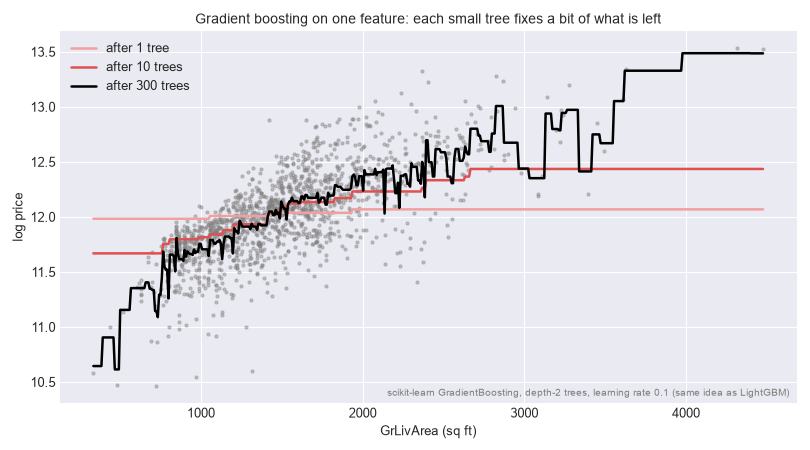

**Blending in one line** → average the log predictions of Lasso and LightGBM.

$$\hat y_{\text{blend}} = \tfrac12\,\hat y_{\text{Lasso}} + \tfrac12\,\hat y_{\text{LightGBM}}$$
- In short → straight lines and step functions make different kinds of mistakes. Where one guesses too high and the other too low, the average lands closer

**Why it works** → if two equally good models made exactly the same mistakes, averaging would gain nothing; if their mistakes were unrelated, the typical error would drop by about 29%. Lasso and LightGBM sit in between.

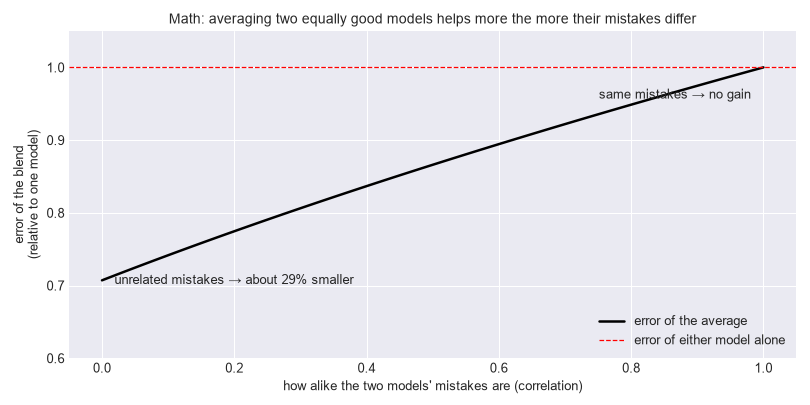

In [ ]:
print('[1/2] LightGBM')
evaluate('LightGBM', make_pipeline(make_preprocessor(), LGBMRegressor(random_state=SEED, **LGBM_PARAMS)))
print('[2/2] Blend (Lasso + LightGBM) / 2')
blend_oof  = (oof_preds[LASSO_NAME] + oof_preds['LightGBM']) / 2
blend_rmse = [rmse(y_log[val], blend_oof[val]) for _, val in folds.split(X_all)]
results['Blend (Lasso + LightGBM)']   = {'CV RMSE (log)': np.mean(blend_rmse), 'fold std': np.std(blend_rmse),
                                         'typical miss %': (np.exp(np.mean(blend_rmse)) - 1) * 100}
oof_preds['Blend (Lasso + LightGBM)'] = blend_oof
leaderboard = pd.DataFrame(results).T.sort_values('CV RMSE (log)')
display(leaderboard.round(4))

In [ ]:
ranked = leaderboard.drop(index='Baseline (average price)').sort_values('CV RMSE (log)', ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(ranked.index, ranked['CV RMSE (log)'], xerr=ranked['fold std'], capsize=3,
        color=[PALETTE['flag'] if name == ranked.index[-1] else PALETTE['soft'] for name in ranked.index])
ax.set(xlabel=f'CV RMSE on log price (baseline = {results["Baseline (average price)"]["CV RMSE (log)"]:.3f})',
       title='Model comparison, same 5 folds (lower is better)')
plt.show()

# [10/11] Diagnostics

**Clue** → the blend is the best model (0.109), but back in [5/11] the log residuals had a left tail (−0.55): cheap houses priced too high.

**I suspect** → the hardest houses are still those cheap ones, plus sales whose price doesn't describe the house, like the 2 partial-sale giants.

**Question** → where does the final model still miss, and is there a pattern?

**Let's break it down** → 1) price every house with a model that never saw it (out-of-fold) 2) list the 8 largest misses 3) compare the median miss by type of sale

**Answer:** My suspicion holds. For most houses it's close: the median miss is **5.0%** on normal sales. The big misses are unusual sales:
- every one of the 8 largest misses is an **unusual sale** (abnormal, family or partial) or a house under \$65,000 in IDOTRR, Sawyer, OldTown or Edwards, and the model priced all of them 70-122% too high
- the median miss is 10.0% for abnormal sales and 12.1% for sales between family members

**Why** → those prices reflect the circumstances of the sale, which no column fully describes.

In [ ]:
best_oof = oof_preds['Blend (Lasso + LightGBM)']
diag = pd.DataFrame({'Id':            train['Id'],
                     'GrLivArea':     train['GrLivArea'],
                     'OverallQual':   train['OverallQual'],
                     'Neighborhood':  train['Neighborhood'],
                     'SaleCondition': train['SaleCondition'],
                     'actual $':      train[TARGET],
                     'predicted $':   np.expm1(best_oof).round(0)})
diag['miss %'] = ((diag['predicted $'] / diag['actual $'] - 1) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(diag['actual $'], diag['predicted $'], s=8, alpha=0.5, color=PALETTE['main'])
axes[0].plot([diag['actual $'].min(), diag['actual $'].max()], [diag['actual $'].min(), diag['actual $'].max()], color=PALETTE['flag'])
axes[0].set(xlabel='actual price ($)', ylabel='predicted price ($)', title='Out-of-fold predictions vs reality')
axes[1].scatter(best_oof, y_log - best_oof, s=8, alpha=0.5, color=PALETTE['main'])
axes[1].axhline(0, color=PALETTE['flag'])
axes[1].set(xlabel='predicted log price', ylabel='residual (log)', title='Residuals vs predicted')
plt.tight_layout()
plt.show()

In [ ]:
display(diag.reindex(diag['miss %'].abs().sort_values(ascending=False).index).head(8))
display(diag.assign(abs_miss=diag['miss %'].abs()).groupby('SaleCondition')['abs_miss']
        .agg(['median', 'size']).rename(columns={'median': 'median |miss %|', 'size': 'houses'}).round(1))

# [11/11] Submission

**Aim** → refit Lasso and LightGBM on every training house and price the 1,459 test houses. It only previews unless you turn it on.

**Question:** How would this score on the leaderboard?

**Answer:** Set `SAVE_SUBMISSION = True` in the top cell to write `submission.csv` for all 1,459 test houses. Until then, the cross-validated blend error above (0.109) is my best local guess of the leaderboard score.

**Last step** → the models predict log price, so every prediction goes back to dollars with $e^{\tilde y} - 1$, the reverse of $\log(1 + y)$ from [3/11].

In [ ]:
"""Optional · Set SAVE_SUBMISSION = True in the top cell to write the CSV."""
show_block('Inputs', {'mode':        'save' if SAVE_SUBMISSION else 'preview',
                      'train rows':  len(X_all),
                      'test rows':   len(X_test),
                      'output file': SUBMISSION_FILE})

In [ ]:
final_lasso = make_pipeline(make_preprocessor(), Lasso(alpha=best_lasso, max_iter=50000)).fit(X_all, y_log)
final_lgbm  = make_pipeline(make_preprocessor(), LGBMRegressor(random_state=SEED, **LGBM_PARAMS)).fit(X_all, y_log)
test_log    = (final_lasso.predict(X_test) + final_lgbm.predict(X_test)) / 2
submission  = pd.DataFrame({'Id': test_raw['Id'], TARGET: np.expm1(test_log)})
display(submission.head(SUBMISSION_PREVIEW))
show_block('Outputs', {'predicted median price': f'${submission[TARGET].median():,.0f}',
                       'predicted range':        f'${submission[TARGET].min():,.0f} - ${submission[TARGET].max():,.0f}'})

In [ ]:
if SAVE_SUBMISSION:
    submission.to_csv(SUBMISSION_FILE, index=False)
    print(f'Saved → {SUBMISSION_FILE}')
else:
    print(f'Preview · {len(submission)} rows · nothing written (SAVE_SUBMISSION = False)')

**Next steps**

- **Leaderboard check** → submit with `SAVE_SUBMISSION = True` and compare the public RMSE with the cross-validated 0.109
- **Unusual sales** → flag or model abnormal, family and partial sales separately: they hold the biggest misses
- **Neighbourhood × size** → interaction terms, since a square foot is worth more in NridgHt than in MeadowV
- **Stacking** → learn the blend weights instead of 50 / 50, and add ElasticNet, SVR or CatBoost
- **Inference** → refit the Lasso-selected features with `statsmodels` OLS for a confidence interval on every coefficient